In [ ]:
# Optional: the tested code lives in backend/src/egress. The cells below do not need it,
# so a failed import here is not a problem (e.g. in Colab there is no ../backend folder).
import sys
sys.path.insert(0, "../backend")
try:
    from src.egress import roads, fire, people, coupling
    print("egress package loaded")
except ImportError as e:
    print("egress package not loaded - fine, the cells below work without it:", e)


15412 вершин, 36935 рёбер
минут до Ипсонаса: 28


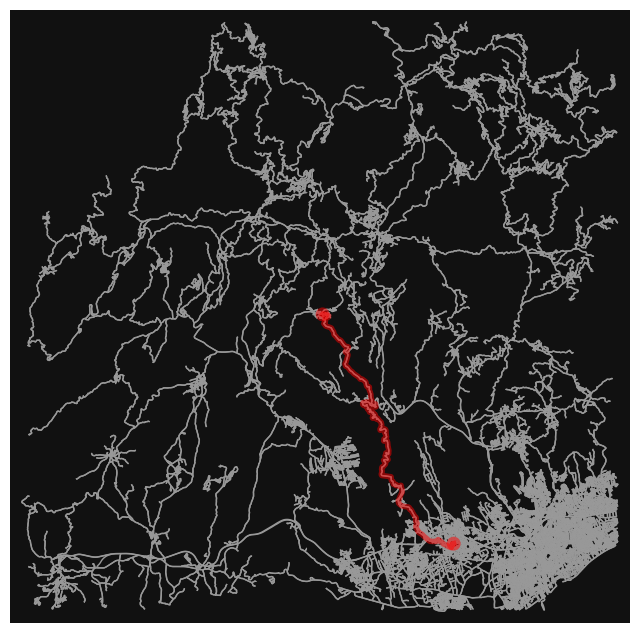

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [2]:
!pip install -q osmnx
import osmnx as ox, networkx as nx

# village = ox.geocode("Lofou, Limassol, Cyprus")
village = (34.815917, 32.875412)
city    = ox.geocode("Ypsonas, Limassol, Cyprus")
G = ox.graph_from_point(village, dist=18000, network_type="drive")
G = ox.routing.add_edge_speeds(G)
G = ox.routing.add_edge_travel_times(G)
print(len(G.nodes), "вершин,", len(G.edges), "рёбер")

s = ox.distance.nearest_nodes(G, X=village[1], Y=village[0])
t = ox.distance.nearest_nodes(G, X=city[1],    Y=city[0])
route = nx.shortest_path(G, s, t, weight="travel_time")
print("минут до Ипсонаса:", round(nx.path_weight(G, route, "travel_time") / 60))
ox.plot_graph_route(G, route, node_size=0)

In [3]:
U = nx.Graph(G.to_undirected())
print("независимых выездов:", nx.edge_connectivity(U, s, t))
print("узкие места:", nx.minimum_edge_cut(U, s, t))

независимых выездов: 2
узкие места: {(5204545067, 5204545064), (262401903, 5204545064)}


независимых выездов: 4


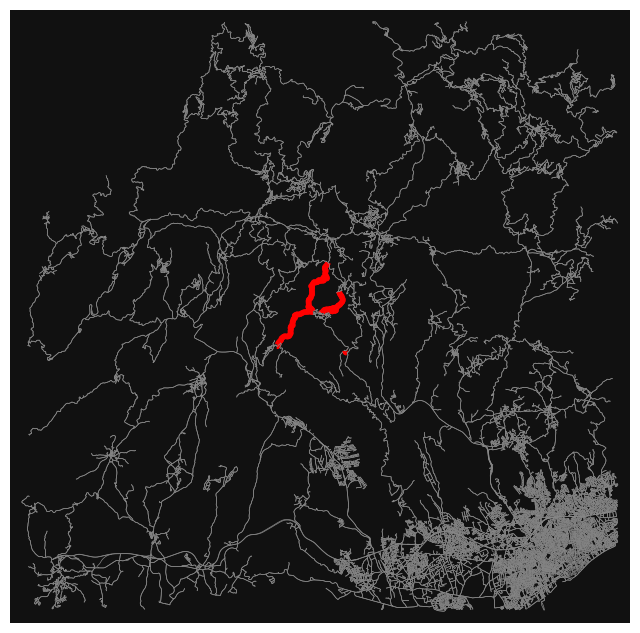

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [4]:
import math
def dist_m(lat1, lon1, lat2, lon2):
    R = 6371000
    p1, p2 = math.radians(lat1), math.radians(lat2)
    a = math.sin((p2-p1)/2)**2 + math.cos(p1)*math.cos(p2)*math.sin(math.radians(lon2-lon1)/2)**2
    return 2 * R * math.asin(math.sqrt(a))

lat0, lon0 = village
inside  = [n for n, d in U.nodes(data=True) if dist_m(lat0, lon0, d["y"], d["x"]) < 400]
outside = [n for n, d in U.nodes(data=True) if dist_m(lat0, lon0, d["y"], d["x"]) > 5000]

H = U.copy()
nx.set_edge_attributes(H, 1, "cap")                       # каждая дорога = 1
H.add_edges_from([("SRC", n) for n in inside],  cap=10**6)
H.add_edges_from([(n, "SINK") for n in outside], cap=10**6)

k, (S, T) = nx.minimum_cut(H, "SRC", "SINK", capacity="cap")
cut = {(u, v) for u in S for v in H[u] if v in T and "SRC" not in (u, v) and "SINK" not in (u, v)}
print("независимых выездов:", k)

ec = ["red" if (u, v) in cut or (v, u) in cut else "#888" for u, v, _ in G.edges(keys=True)]
ew = [4 if c == "red" else 0.5 for c in ec]
ox.plot_graph(G, edge_color=ec, edge_linewidth=ew, node_size=0)

In [9]:
b = ox.features_from_point(village, tags={"building": True}, dist=500)
print("зданий:", len(b))

# print(b["building"].value_counts())
area = b.to_crs(32636).area          # площадь каждого здания в м²
# print(area.describe())               # разброс площадей
print('--------')
homes = (area > 40).sum()
print("зданий больше 40 м²:", homes)

зданий: 206
--------
зданий больше 40 м²: 187


In [7]:
homes      = 187    # ← подставьте своё число жилых домов
cars       = homes * 1.5      # допущение: 1,5 машины на дом
capacity   = 700              # машин в час по узкой горной дороге (допущение)
prep_min   = 30               # сколько минут люди собираются (допущение)
drive_min  = 28               # ← время маршрута до Ипсонаса из шага 2

queue_min = cars / capacity * 60
print("в очереди на выезд:", round(queue_min), "мин")
print("всего до безопасности:", round(prep_min + queue_min + drive_min), "мин")

в очереди на выезд: 24 мин
всего до безопасности: 82 мин


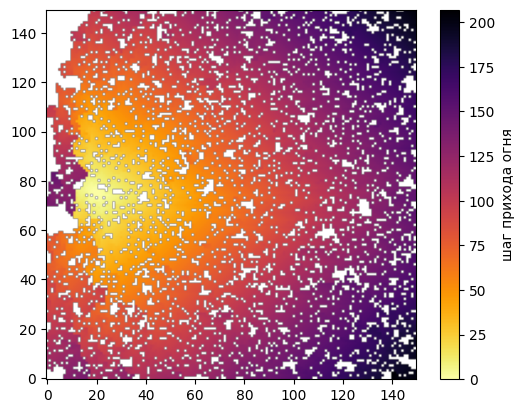

In [8]:
import numpy as np, matplotlib.pyplot as plt

def shift(a, di, dj):
    """Сдвиг массива на (di, dj) без заворачивания через край."""
    out = np.zeros_like(a)
    H, W = a.shape
    out[max(di,0):H+min(di,0), max(dj,0):W+min(dj,0)] = \
        a[max(-di,0):H+min(-di,0), max(-dj,0):W+min(-dj,0)]
    return out

def simulate_fire(fuel, start, wind=(0, 1), base=0.7, wind_k=0.25, steps=600, seed=0):
    """fuel — где есть растительность (bool), start — клетка (i, j),
    wind — куда дует ветер: (1,0) на север, (0,1) на восток.
    Возвращает шаг прихода огня в каждую клетку (inf — не сгорела)."""
    rng = np.random.default_rng(seed)
    w = np.array(wind, float)
    if np.linalg.norm(w) > 0:
        w /= np.linalg.norm(w)
    state = np.zeros(fuel.shape, np.int8)        # 0 цело, 1 горит, 2 сгорело
    arrival = np.full(fuel.shape, np.inf)
    i, j = start
    state[i-1:i+2, j-1:j+2] = 1                  # поджигаем пятно 3×3
    arrival[i-1:i+2, j-1:j+2] = 0
    for step in range(1, steps):
        burning = state == 1
        if not burning.any():
            break                                # огонь погас
        new = np.zeros_like(burning)
        for d in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
            p = base + wind_k * np.dot(d, w)     # по ветру 0.95, против 0.45, вбок 0.7
            new |= shift(burning, *d) & (rng.random(fuel.shape) < p)
        new &= fuel & (state == 0)
        state[burning] = 2; state[new] = 1; arrival[new] = step
    return arrival

N = 150
fuel = np.random.default_rng(1).random((N, N)) < 0.85
arr = simulate_fire(fuel, (75, 20), wind=(0, 1))
plt.imshow(arr, cmap="inferno_r", origin="lower")
plt.colorbar(label="шаг прихода огня"); plt.show()

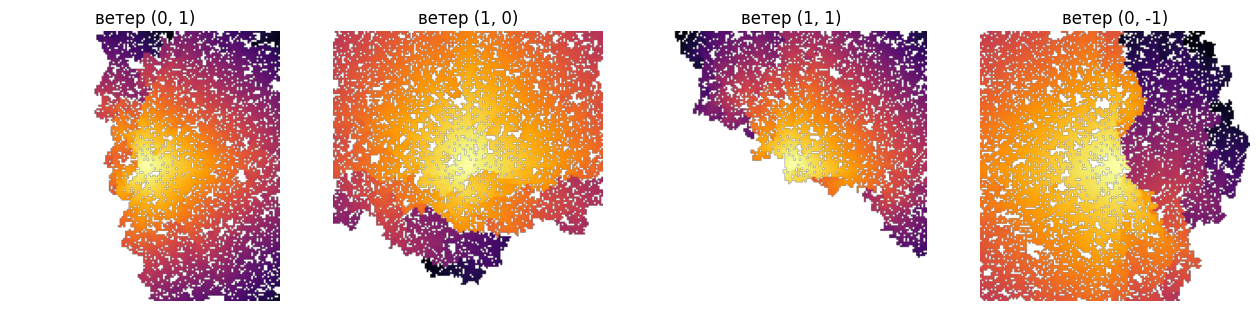

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, w in zip(axes, [(0, 1), (1, 0), (1, 1), (0, -1)]):
    a = simulate_fire(fuel, (75, 75), wind=w)
    ax.imshow(a, cmap="inferno_r", origin="lower"); ax.set_title(f"ветер {w}"); ax.axis("off")
plt.show()

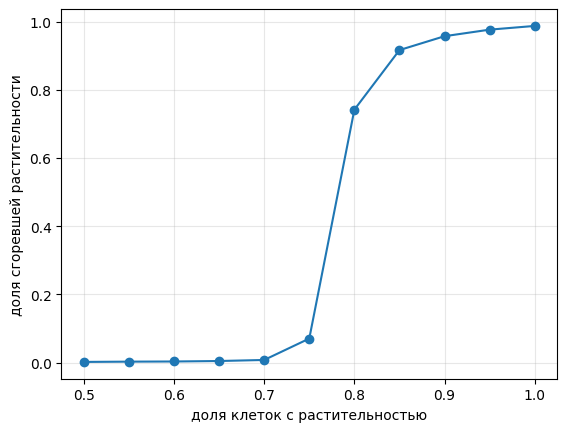

In [11]:
dens = np.arange(0.5, 1.01, 0.05)
share = []
for p in dens:
    runs = []
    for s in range(5):
        f = np.random.default_rng(s).random((N, N)) < p
        a = simulate_fire(f, (75, 75), wind_k=0, seed=s)
        runs.append(np.isfinite(a).sum() / f.sum())
    share.append(np.mean(runs))
plt.plot(dens, share, "o-")
plt.xlabel("доля клеток с растительностью"); plt.ylabel("доля сгоревшей растительности")
plt.grid(alpha=0.3); plt.show()

## Step 0, final part: couple the fire to the roads
Run the cells below after the cells above (they reuse `G`, `village`, `city`, `fuel`, `simulate_fire`, `cars`, `capacity`, `prep_min`).
For each random fire (ignition point + wind) it finds when every road node is lost, then the **latest minute the last car can leave** and the **latest alert time** that follows.

In [ ]:
import heapq, time
import numpy as np
import matplotlib.pyplot as plt

# ---- assumptions (all of these are knobs to calibrate later) ----
CELL_M       = 100    # size of one fire-grid cell in metres -> 150 cells = a 15 km square centred on the village
MIN_PER_STEP = 2.0    # minutes of real fire time per simulation step (ASSUMPTION, calibrate on the 2025 fire)
MARGIN_MIN   = 5      # a road node counts as lost this many minutes BEFORE the fire reaches it
N_GRID       = fuel.shape[0]
queue_min    = cars / capacity * 60      # from the step-4 cell: how long the car queue takes to leave

lat0, lon0 = village

def to_cell(lat, lon):
    """lat/lon -> (i, j) on the fire grid. i = north, j = east, village in the centre."""
    x = (lon - lon0) * 111_320 * np.cos(np.radians(lat0))
    y = (lat - lat0) * 110_540
    return int(round(N_GRID / 2 + y / CELL_M)), int(round(N_GRID / 2 + x / CELL_M))

# road graph as plain arrays (fast)
nodes = list(G.nodes)
idx   = {n: k for k, n in enumerate(nodes)}
cell  = np.array([to_cell(G.nodes[n]["y"], G.nodes[n]["x"]) for n in nodes])
in_grid = (cell[:, 0] >= 0) & (cell[:, 0] < N_GRID) & (cell[:, 1] >= 0) & (cell[:, 1] < N_GRID)

adj = [[] for _ in nodes]
for u, v, d in G.edges(data=True):                  # directed: one-way roads are respected
    adj[idx[u]].append((idx[v], d["travel_time"] / 60))     # minutes

# the percolation loop (`for s in range(5)`) overwrites `s`, so recompute the two route nodes here
s = ox.distance.nearest_nodes(G, X=village[1], Y=village[0])
t = ox.distance.nearest_nodes(G, X=city[1],    Y=city[0])
src, dst = idx[s], idx[t]                           # village node and Ypsonas node from step 2
print("nodes on the fire grid:", int(in_grid.sum()), "of", len(nodes))

In [ ]:
def buffer_min(arr, r=1):
    """Earliest fire arrival within r cells. Roads usually run through cells with no fuel,
    so a road 'burns' when the fire reaches the cells next to it."""
    P = np.pad(arr, r, constant_values=np.inf)
    out = np.full_like(arr, np.inf)
    for di in range(-r, r + 1):
        for dj in range(-r, r + 1):
            out = np.minimum(out, P[r + di : r + di + arr.shape[0], r + dj : r + dj + arr.shape[1]])
    return out

def node_cut_times(arrival):
    """Minute (after ignition) when each road node is lost. inf = fire never gets there."""
    b = buffer_min(arrival) * MIN_PER_STEP
    cut = np.full(len(nodes), np.inf)
    cut[in_grid] = b[cell[in_grid, 0], cell[in_grid, 1]]
    return cut - MARGIN_MIN

def reachable(depart, cut, a, b):
    """Can a car leaving a at minute `depart` reach b without entering a node after it is lost?"""
    if depart >= cut[a]:
        return False
    best = {a: depart}
    heap = [(depart, a)]
    while heap:
        tm, u = heapq.heappop(heap)
        if u == b:
            return True
        if tm > best.get(u, np.inf):
            continue
        for v, w in adj[u]:
            tv = tm + w
            if tv < cut[v] and tv < best.get(v, np.inf):
                best[v] = tv
                heapq.heappush(heap, (tv, v))
    return False

def latest_departure(cut, a, b, hi=600):
    """Latest minute (after ignition) a car can still leave a and make it to b.
    -inf: already impossible at ignition.  +inf: the fire never blocks the way."""
    if not reachable(0, cut, a, b):
        return -np.inf
    if reachable(hi, cut, a, b):
        return np.inf
    lo = 0.0
    for _ in range(12):                      # binary search: later departure = fewer open roads
        mid = (lo + hi) / 2
        if reachable(mid, cut, a, b):
            lo = mid
        else:
            hi = mid
    return lo

WINDS = [(0, 1), (1, 1), (1, 0), (1, -1), (0, -1), (-1, -1), (-1, 0), (-1, 1)]

def run_scenario(seed):
    rng = np.random.default_rng(seed)
    ang, r = rng.uniform(0, 2 * np.pi), rng.uniform(500, 6000) / CELL_M      # ignition 0.5-6 km from the village
    i = int(np.clip(N_GRID / 2 + r * np.sin(ang), 2, N_GRID - 3))
    j = int(np.clip(N_GRID / 2 + r * np.cos(ang), 2, N_GRID - 3))
    wind = WINDS[rng.integers(len(WINDS))]
    arrival = simulate_fire(fuel, (i, j), wind=wind, seed=int(seed))
    cut = node_cut_times(arrival)
    d_star = latest_departure(cut, src, dst)                # latest minute the LAST car may leave the village
    return {"seed": seed, "ignition": (i, j), "wind": wind, "cut": cut,
            "d_star": d_star,
            "alert_latest": d_star - prep_min - queue_min}   # latest alert time (min after ignition)

In [ ]:
t0 = time.time()
results = [run_scenario(sd) for sd in range(100)]
print(f"{len(results)} scenarios in {time.time() - t0:.0f} s")

al = np.array([r["alert_latest"] for r in results])
print(f"prep {prep_min} min + queue {queue_min:.0f} min before the last car leaves")
print(f"fire never blocks the route:                {np.isposinf(al).mean():.0%}")
print(f"impossible even if alerted at ignition:     {(al < 0).mean():.0%}")
print(f"alert needed within 30 min of ignition:     {((al >= 0) & (al < 30)).mean():.0%}")
print(f"alert needed within 60 min of ignition:     {((al >= 0) & (al < 60)).mean():.0%}")

fin = al[np.isfinite(al)]
plt.hist(fin, bins=20); plt.axvline(0, color="red")
plt.xlabel("latest alert, minutes after ignition (left of red = impossible)"); plt.ylabel("scenarios")
plt.show()

In [ ]:
from matplotlib.colors import to_hex

def edge_colors(cut):
    cm, out = plt.get_cmap("RdYlGn"), []
    for u, v, k in G.edges(keys=True):
        c = min(cut[idx[u]], cut[idx[v]])
        out.append("#bbbbbb" if not np.isfinite(c) else to_hex(cm(min(max(c, 0), 180) / 180)))   # red = lost early
    return out

worst = min((r for r in results if np.isfinite(r["alert_latest"])), key=lambda r: r["alert_latest"])
print("worst scenario: ignition", worst["ignition"], "wind", worst["wind"], "latest alert", round(worst["alert_latest"]), "min")
ox.plot_graph(G, edge_color=edge_colors(worst["cut"]), edge_linewidth=0.8, node_size=0, bgcolor="white")